# Privacy-preserving event summaries

Produce a diagnostic summary from an allowlist of fields.

Use a small schema that emits only fields needed for aggregate error counts. Reconstruct a new record rather than recursively copying unknown context. A count can still reveal information about a very small population.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

aggregate counts [(('reader', 'ok'), 2), (('writer', 'ok'), 1), (('writer', 'retry'), 1)]


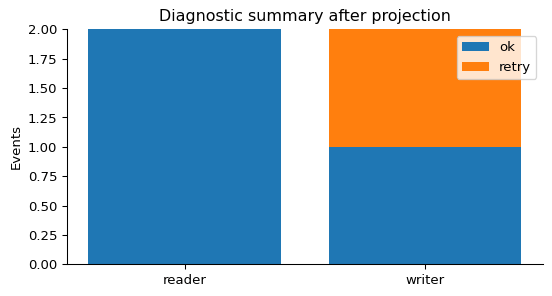

In [2]:
rows = [
    {"component": "reader", "status": "ok", "account": "demo-a", "comment": "sample"},
    {"component": "writer", "status": "retry", "account": "demo-b"},
    {"component": "reader", "status": "ok", "extra": {"token": "fixture"}},
    {"component": "writer", "status": "ok"},
]
allowed = {"reader", "writer"}
states = {"ok", "retry"}
public = [
    {"component": r["component"], "status": r["status"]}
    for r in rows
    if r.get("component") in allowed and r.get("status") in states
]
summary = Counter((r["component"], r["status"]) for r in public)
print("aggregate counts", sorted(summary.items()))
assert all(set(r) == {"component", "status"} for r in public)
fig, ax = plt.subplots(figsize=(5.7, 3), constrained_layout=True)
names = sorted(allowed)
bottom = np.zeros(len(names))
for status in sorted(states):
    vals = np.array([summary[(n, status)] for n in names])
    ax.bar(names, vals, bottom=bottom, label=status)
    bottom += vals
ax.set(ylabel="Events", title="Diagnostic summary after projection")
ax.legend()
plt.show()

## Interpreting the result

The output preserves the fields needed for this count. Free text and nested metadata have no route into the exported records.

## Exercise

Add an unknown component and specify how rejected schema values should be counted without exposing the original record.

## References

[OWASP, Logging Cheat Sheet](https://cheatsheetseries.owasp.org/cheatsheets/Logging_Cheat_Sheet.html)